# **A Finance Starter Kit**

## Introduction

This notebook introduces the fundamental Python tools and concepts used in **quantitative finance** and **data analysis**.  
It covers how to download, manipulate, and analyze financial time series using Python’s most popular libraries —  
**pandas**, **NumPy**, **Matplotlib**, and **yfinance**.  

Through a series of practical examples, the notebook demonstrates:
- How to fetch market data (e.g., stocks, indexes) from online sources.
- How to compute **returns**, **risk measures**, and **performance metrics**.
- How to visualize key financial concepts such as **Wealth Index**, **Volatility**, and **Drawdowns**.

This project serves as a foundation for anyone looking to build more advanced quantitative models,  
such as **GARCH volatility forecasting**, **portfolio optimization**, or **machine learning–based trading systems**.

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

### **Data**

In [3]:
# 1. Importing data from a CSV file, stored in the data folder
# pd.read_csv('data/name_of_the_file.csv')

In [2]:
# 2. Importing data using yfinance (AAPL)
import yfinance as yf
aapl = yf.download(tickers='AAPL', start='2020-01-01', end='2025-01-01')
aapl.head(3)

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2020-01-02,72.468231,72.528551,71.223229,71.476570,135480400
2020-01-03,71.763733,72.523762,71.539345,71.696175,146322800
2020-01-06,72.335564,72.374169,70.634547,70.885479,118387200


In [4]:
# For a better visualization
aapl.columns = aapl.columns.droplevel(1) # drop the column with repetition of the tickers
print(aapl.head(3))
print(aapl.tail(3))

Price           Close       High        Low       Open     Volume
Date                                                             
2020-01-02  72.468231  72.528551  71.223229  71.476570  135480400
2020-01-03  71.763733  72.523762  71.539345  71.696175  146322800
2020-01-06  72.335564  72.374169  70.634547  70.885479  118387200
Price            Close        High         Low        Open    Volume
Date                                                                
2024-12-27  254.439209  257.535222  251.920601  256.669114  42355300
2024-12-30  251.064484  252.358634  249.621015  251.094347  35557500
2024-12-31  249.292511  252.139635  248.306963  251.303420  39480700


In [10]:
# 3. Another example, if you want to download at the same time data for all the S&P 500 stocks, you can do:
# Read the first HTML table from the Wikipedia page containing the S&P 500 companies.
# The 'storage_options' parameter adds a fake browser User-Agent to avoid HTTP 403 errors (Wikipedia blocks anonymous requests).
sp500 = pd.read_html("https://en.wikipedia.org/wiki/List_of_S%26P_500_companies", storage_options={"User-Agent": "Mozilla/5.0"})[0]
display(sp500.head(10))  # Display the first 10 symbols

,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888)
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989
5,ADBE,Adobe Inc.,Information Technology,Application Software,"San Jose, California",1997-05-05,796343,1982
6,AMD,Advanced Micro Devices,Information Technology,Semiconductors,"Santa Clara, California",2017-03-20,2488,1969
7,AES,AES Corporation,Utilities,Independent Power Producers & Energy Traders,"Arlington, Virginia",1998-10-02,874761,1981
8,AFL,Aflac,Financials,Life & Health Insurance,"Columbus, Georgia",1999-05-28,4977,1955
9,A,Agilent Technologies,Health Care,Life Sciences Tools & Services,"Santa Clara, California",2000-06-05,1090872,1999


In [11]:
# Replace dots in ticker symbols with dashes, since Yahoo Finance uses '-' instead of '.'
# Example: 'BRK.B' (Wikipedia format) -> 'BRK-B' (Yahoo Finance format)
sp500['Symbol'] = sp500['Symbol'].str.replace('.','-')

In [12]:
# Now:
# - Select the 'Symbol' column from the DataFrame sp500
# - '.unique()' -> removes any duplicated tickers (keeps only unique values)
# - '.tolist()' -> converts the NumPy array into a standard Python list
symbols_list = sp500['Symbol'].unique().tolist()
# We can't use 'head()': with a list we use this:
symbols_list[:10]

['MMM', 'AOS', 'ABT', 'ABBV', 'ACN', 'ADBE', 'AMD', 'AES', 'AFL', 'A']

In [15]:
# Downloading the data for all the stocks in the S&P 500
# Another interesting thing: if you want to download data for the previous year, starting from a given end date
import datetime as dt

END_DATE = "2025-01-01"
START_DATE = pd.to_datetime(END_DATE) - pd.DateOffset(days=365)

raw = yf.download(
    tickers=symbols_list,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    group_by="column",
    threads=True,
)

# Keep only prices (if you want all OHLCV later, skip this selection)
# raw has columns like: Open/High/Low/Close/Volume for each ticker (depending on yfinance version)
# Here we stack the full panel; alternatively pick ["Close"] only.
raw = raw.dropna(axis=1, how="all")  # drop tickers with no data at all

# Stack to long format (MultiIndex: date, ticker)
df = raw.stack(future_stack=True)
df.index.names = ["date", "ticker"]
df.columns = df.columns.str.lower()

df

[*****                 11%                       ]  54 of 503 completed$Q: possibly delisted; no price data found  (1d 2024-01-02 00:00:00 -> 2025-01-01) (Yahoo error = "Data doesn't exist for startDate = 1704171600, endDate = 1735707600")
[******                12%                       ]  61 of 503 completed$SNDK: possibly delisted; no price data found  (1d 2024-01-02 00:00:00 -> 2025-01-01) (Yahoo error = "Data doesn't exist for startDate = 1704171600, endDate = 1735707600")
[*********************100%***********************]  503 of 503 completed

4 Failed downloads:
['Q', 'SNDK']: possibly delisted; no price data found  (1d 2024-01-02 00:00:00 -> 2025-01-01) (Yahoo error = "Data doesn't exist for startDate = 1704171600, endDate = 1735707600")
['MET', 'INTU']: TypeError("'NoneType' object is not subscriptable")


Price                   close        high         low        open      volume
date       ticker                                                            
2024-01-02 A       136.693512  138.506237  135.865966  136.141814   1441600.0
           AAPL    183.903229  186.677036  182.169601  185.399096  82488700.0
           ABBV    148.974808  149.273086  144.267492  144.388661   8059900.0
           ABNB    134.479996  135.600006  133.339996  134.429993   3485200.0
           ABT     105.697922  106.804456  105.418882  105.418882   5058600.0
...                       ...         ...         ...         ...         ...
2024-12-31 XYZ      84.989998   88.000000   84.820000   87.720001   4989400.0
           YUM     131.612045  132.230070  130.719324  131.543368   1217100.0
           ZBH     104.596786  105.458279  103.933342  104.874054    683300.0
           ZBRA    386.220001  387.410004  381.750000  383.420013    327900.0
           ZTS     160.793213  161.602466  159.747117  160.763608   1327400.0

[125748 rows x 5 columns]

In [16]:
# Save the data in a CSV file
df.to_csv('sp500.csv')

### **Pandas Series and DataFrames**

In **pandas**, data is organized primarily in two key structures: **Series** and **DataFrames**.

#### **Series**
A **Series** is a one-dimensional labeled array that can hold data of any type — integers, floats, strings, etc.  
It has two main components:
- **Values**: the actual data.
- **Index**: labels that identify each value.

In [17]:
# Example
s = pd.Series([10, 20, 30], index=['A', 'B', 'C'])
print(s)

A    10
B    20
C    30
dtype: int64


#### **DataFrame**

A **DataFrame** is a two-dimensional labeled data structure — like a table in Excel —
where each column is a Series and all columns share the same index.

In [18]:
# Example
data = {'Price':[10, 20, 30], 
        'Quantity':[5, 3, 8]}

dataframe = pd.DataFrame(data, index=['A', 'B', 'C'])
print(dataframe)

   Price  Quantity
A     10         5
B     20         3
C     30         8


In [19]:
print(type(aapl))
print(type(aapl['Close']))

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.series.Series'>


**dropna()** -> is a pandas method used to drop (delete) rows or columns with missing data.  
**inplace=True** -> means that the operation is performed directly on the original DataFrame, without creating a new one.

In [20]:
# You can read the data from the CSV file
df = pd.read_csv('sp500.csv')
df

,date,ticker,close,high,low,open,volume
0,2024-01-02,A,136.693512,138.506237,135.865966,136.141814,1441600.0
1,2024-01-02,AAPL,183.903229,186.677036,182.169601,185.399096,82488700.0
2,2024-01-02,ABBV,148.974808,149.273086,144.267492,144.388661,8059900.0
3,2024-01-02,ABNB,134.479996,135.600006,133.339996,134.429993,3485200.0
4,2024-01-02,ABT,105.697922,106.804456,105.418882,105.418882,5058600.0
...,...,...,...,...,...,...,...
125743,2024-12-31,XYZ,84.989998,88.000000,84.820000,87.720001,4989400.0
125744,2024-12-31,YUM,131.612045,132.230070,130.719324,131.543368,1217100.0
125745,2024-12-31,ZBH,104.596786,105.458279,103.933342,104.874054,683300.0
125746,2024-12-31,ZBRA,386.220001,387.410004,381.750000,383.420013,327900.0


In [21]:
type(df)

pandas.core.frame.DataFrame

### **Returns**

In [22]:
# Percentage returns: r_t = (P_t / P_{t-1}) - 1
aapl['ret_pct'] = aapl['Close'].pct_change()

# Log returns: r_t = ln(P_t) - ln(P_{t-1})
aapl['ret_log'] = np.log(aapl['Close']).diff()

# Dropping NA values
aapl = aapl.dropna()

aapl.head(5)

Price,Close,High,Low,Open,Volume,ret_pct,ret_log
Date,,,,,,,
2020-01-03,71.763733,72.523762,71.539345,71.696175,146322800,-0.009721,-0.009769
2020-01-06,72.335564,72.374169,70.634547,70.885479,118387200,0.007968,0.007937
2020-01-07,71.995361,72.600968,71.775796,72.345212,108872000,-0.004703,-0.004714
2020-01-08,73.153488,73.455087,71.698574,71.698574,132079200,0.016086,0.015958
2020-01-09,74.707329,74.900349,73.879742,74.130668,170108400,0.021241,0.021018


Text(0, 0.5, 'Daily Returns (%)')

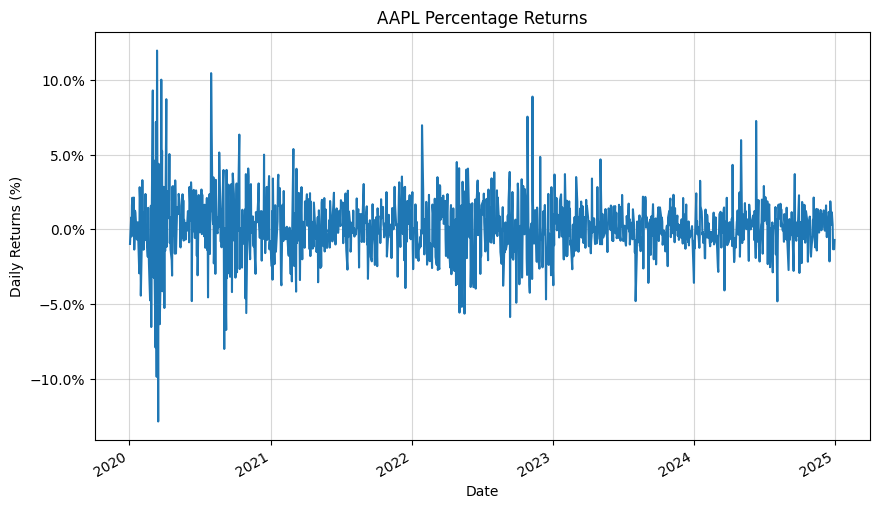

In [23]:
import matplotlib.ticker as mtick

aapl['ret_pct'].plot(title='AAPL Percentage Returns', figsize=(10, 6))
plt.grid(alpha=0.5)
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.xlabel('Date')
plt.ylabel('Daily Returns (%)')

In [24]:
# Using only [], we get ret_pct as a Series
ret_pct = aapl['ret_pct']
ret_pct.head(5)

Date
2020-01-03   -0.009721
2020-01-06    0.007968
2020-01-07   -0.004703
2020-01-08    0.016086
2020-01-09    0.021241
Name: ret_pct, dtype: float64

In [25]:
ret_pct.describe().round(4)

count    1257.0000
mean        0.0012
std         0.0200
min        -0.1286
25%        -0.0084
50%         0.0012
75%         0.0120
max         0.1198
Name: ret_pct, dtype: float64

In [26]:
# Otherwise, using double [[]], we get a DataFrame
ret_log = aapl[['ret_log']]
ret_log.head(5)

Price,ret_log
Date,
2020-01-03,-0.009769
2020-01-06,0.007937
2020-01-07,-0.004714
2020-01-08,0.015958
2020-01-09,0.021018


In [27]:
# Another example
returns_df = aapl[['ret_pct', 'ret_log']]
returns_df.head(5)

Price,ret_pct,ret_log
Date,,
2020-01-03,-0.009721,-0.009769
2020-01-06,0.007968,0.007937
2020-01-07,-0.004703,-0.004714
2020-01-08,0.016086,0.015958
2020-01-09,0.021241,0.021018


In [28]:
# We can use .loc and .iloc to filter data:
# -> .loc for a label-based indexing
# -> .iloc for a position-based indexing
print(f'This is the .loc:\n', aapl.loc['2021-01-04'])  # Data for a specific date
print(f'\nThis is the .iloc:\n', aapl.iloc[5])         # The 5th row

This is the .loc:
 Price
Close      1.259745e+02
High       1.300630e+02
Low        1.233948e+02
Open       1.299754e+02
Volume     1.433019e+08
ret_pct   -2.471928e-02
ret_log   -2.502993e-02
Name: 2021-01-04 00:00:00, dtype: float64

This is the .iloc:
 Price
Close      7.487623e+01
High       7.544083e+01
Low        7.437437e+01
Open       7.494138e+01
Volume     1.406448e+08
ret_pct    2.260816e-03
ret_log    2.258264e-03
Name: 2020-01-10 00:00:00, dtype: float64


In [29]:
# Both .loc and .iloc can be used for slicing, if you want to select a range of rows or columns
# For example:
aapl.loc['2021-01-04':'2021-01-10']  # Slicing rows by date range'

Price,Close,High,Low,Open,Volume,ret_pct,ret_log
Date,,,,,,,
2021-01-04,125.974464,130.062961,123.394814,129.975354,143301900,-0.024719,-0.025030
2021-01-05,127.531982,128.242613,125.020474,125.468268,97664900,0.012364,0.012288
2021-01-06,123.239059,127.570927,123.024899,124.329329,155088000,-0.033662,-0.034241
2021-01-07,127.444359,128.135516,124.465598,124.952324,109578200,0.034123,0.033554
2021-01-08,128.544373,129.108977,126.772682,128.914274,105158200,0.008631,0.008594


In [30]:
aapl.iloc[5:10]                    # Slicing rows by position

Price,Close,High,Low,Open,Volume,ret_pct,ret_log
Date,,,,,,,
2020-01-10,74.876228,75.440829,74.374370,74.941378,140644800,0.002261,0.002258
2020-01-13,76.475922,76.502466,75.074089,75.192321,121532000,0.021365,0.021139
2020-01-14,75.443237,76.623097,75.320190,76.413185,161954400,-0.013503,-0.013595
2020-01-15,75.119904,76.123626,74.688012,75.242958,121923600,-0.004286,-0.004295
2020-01-16,76.060913,76.171907,75.300884,75.662804,108829200,0.012527,0.012449


### **Measures of Risk**

**Variance**

$\sigma^2 = \frac{1}{N} \sum_{i=1}^{N} (R_i - \mu)^2$

**Standard Deviation**

$\sigma = \sqrt{\sigma^2}$

*Standard Deviation is the square root of the variance.*

In [31]:
std = ret_log.std() # Standard Deviation
print(f'Standard Deviation: {std.iloc[0]:.4%}')

Standard Deviation: 1.9940%


### **Annualized Returns**
For daily returns, the compound annualized return can be calculated using the formula:
${R}_{annualized} = (1 + {r}_{d})^{252} - 1$, or in general terms: $R_{\text{annualized}} = \left( \prod_{i=1}^{N} (1 + r_i) \right)^{\frac{252}{N}} - 1$

In [32]:
def annualized_returns(r, periods_per_year=252):
    """
    Annualized returns based on the data frequency.
    
    Parameters:
    -> r: pandas Series or DataFrame
       Series of returns (daily, monthly, etc.)
    -> periods_per_year: int, default=252
       Number of periods in a year (252 for daily data, 12 for monthly data, etc.)
    """
    n_periods = r.shape[0]
    compounded_growth = (1+r).prod()
    return compounded_growth ** (periods_per_year / n_periods) - 1

In [33]:
ann_ret = annualized_returns(ret_pct)
print(f'Annualized Return: {ann_ret:.4%}')

Annualized Return: 28.1057%


### **Annualized Volatility**
The annualized volatility can be calculated using the formula:
$\sigma_{\text{annualized}} = \sigma_d \times \sqrt{252}$.  
Let's compute a function to do this:

In [34]:
def annualized_volatility(r, periods_per_year=252):
    return r.std() * np.sqrt(periods_per_year)

In [35]:
ann_vol = annualized_volatility(ret_pct)
print(f'Annualized Volatility: {ann_vol:.4%}')

Annualized Volatility: 31.6786%


### **Raw Sharpe Ratio**
Sharpe Ratio is a measure of risk-adjusted return, calculated as the ratio of the excess return of an investment to its standard deviation (volatility).  
The formula for the Sharpe Ratio is:
$S = \frac{R_p - R_f}{\sigma_p}$.  
Otherwise, we can calculate it using $\textit{annualized returns}$ and $\textit{annualized volatility}$ as follows:


In [36]:
# Raw Sharpe Ratio
sharpe_ratio = ann_ret / ann_vol
print(f'Sharpe Ratio: {sharpe_ratio:.4f}')

Sharpe Ratio: 0.8872


### **Wealth Index**

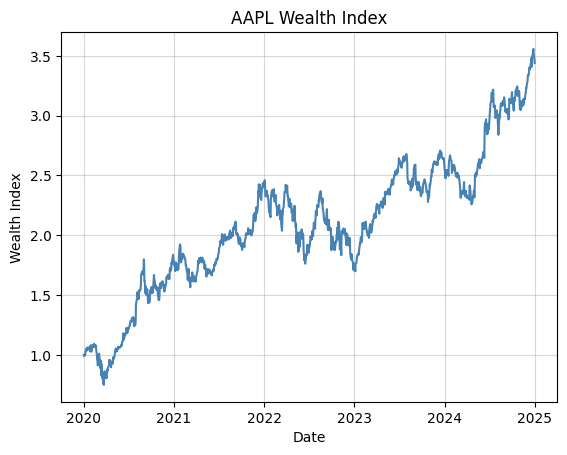

In [37]:
wealth_index = (1 + ret_pct).cumprod()
start_date = wealth_index.index.min() - pd.DateOffset(1)
wealth_index = pd.concat([pd.Series([1], index=[start_date]), wealth_index])
plt.plot(wealth_index, color='steelblue')
plt.title('AAPL Wealth Index')
plt.xlabel('Date')
plt.ylabel('Wealth Index')
plt.grid(alpha=0.5)

### **Drawdowns**
First of all, let's define $\textit{Drawdowns}$: this is the return from the previous peak to the present value.  
Therefore, we can find the previous peak using this method:

In [38]:
previous_peaks = wealth_index.cummax()
# .cummax() is just a cumulative maximum function, which will set each value equal to the highest data point on or before each respective date.

In [39]:
# Now, we can calculate the drawdowns as follows:
drawdowns = (wealth_index - previous_peaks) / previous_peaks
drawdowns.head(10)

2020-01-02    0.000000
2020-01-03   -0.009721
2020-01-06   -0.001831
2020-01-07   -0.006525
2020-01-08    0.000000
2020-01-09    0.000000
2020-01-10    0.000000
2020-01-13    0.000000
2020-01-14   -0.013503
2020-01-15   -0.017731
dtype: float64

In [40]:
max_drawdown = drawdowns.min()
max_drawdown_date = drawdowns.idxmin()
print(f"Max Drawdown: {max_drawdown:.2%} on {max_drawdown_date.date()}")

Max Drawdown: -31.43% on 2020-03-23


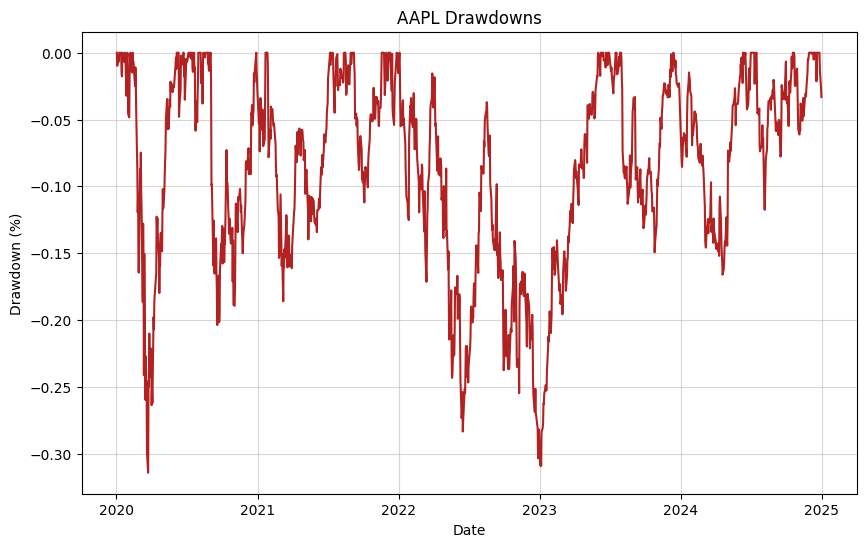

In [41]:
# Plotting the drawdowns
plt.figure(figsize=(10, 6))
plt.plot(drawdowns, color='firebrick')
plt.title('AAPL Drawdowns')
plt.xlabel('Date')
plt.ylabel('Drawdown (%)')
plt.grid(alpha=0.5)
plt.show()

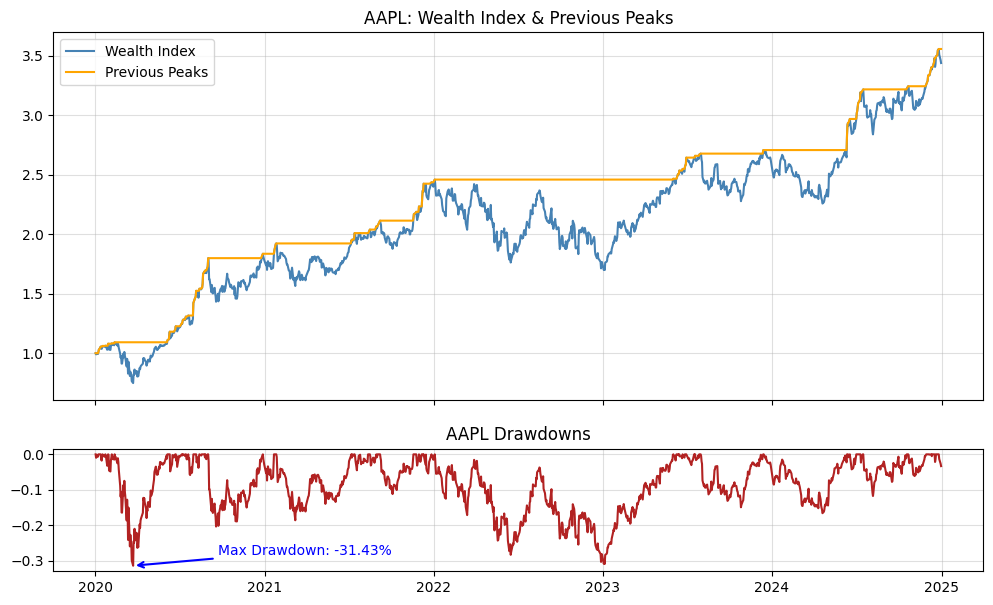

In [42]:
# Plotting wealth index, previous peaks, and drawdowns
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                                gridspec_kw={"height_ratios": [3, 1]})

ax1.plot(wealth_index, label="Wealth Index", color="steelblue")
ax1.plot(previous_peaks, label="Previous Peaks", color="orange")
ax1.set_title("AAPL: Wealth Index & Previous Peaks")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.4)

ax2.plot(drawdowns, color="firebrick")
ax2.set_title("AAPL Drawdowns")
ax2.grid(alpha=0.4)

# Annotate max drawdown on the wealth index plot
max_dd = drawdowns.min()
max_dd_date = drawdowns.idxmin()
ax2.annotate(f"Max Drawdown: {max_dd:.2%}",
             xy=(max_dd_date, max_dd), # point to annotate
             xytext=(max_dd_date + pd.DateOffset(months=6), max_dd*0.9), # text position: 'months=6' moves the text 6 months to the right, 0.9 moves it 10% up from the drawdown value
             arrowprops=dict(arrowstyle="->", lw=1.5, color="blue"),
             color="blue")
plt.show()